In [1]:
from pathlib import Path
from datetime import timedelta
import sys
import time
import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import plotly.express as px

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
REP = ROOT / "reports"
if str(ROOT / "src") not in sys.path:
    sys.path.append(str(ROOT / "src"))
from features import construir_features, FEATS, CAT_FEATS
from censura import clasificar_ceros

H = 28
df = pl.read_parquet(PROC / "m5_CA_1.parquet").with_columns(pl.col("id").cast(pl.Utf8))
seg = pl.read_parquet(PROC / "segmentacion_CA_1.parquet")
mascara_dev = pl.read_parquet(PROC / "mascara_CA_1.parquet")
ids_validos = (pd.read_parquet(PROC / "cv_baselines_CA_1.parquet", columns=["unique_id"])
                 ["unique_id"].unique().tolist())

test_end = pd.Timestamp(df["date"].max())
test_start = test_end - timedelta(days=H - 1)
dev_end = test_start - timedelta(days=1)
df = df.filter(pl.col("id").is_in(ids_validos))

print("Entrenamiento hasta:", dev_end.date(), "| prueba final:", test_start.date(), "→", test_end.date())
print("Series:", df["id"].n_unique())

Entrenamiento hasta: 2016-04-24 | prueba final: 2016-04-25 → 2016-05-22
Series: 3041


In [2]:
sim = pd.read_csv(REP / "simulacion_inventario_volumen_CA_1.csv")
H_BASE, M_BASE = 0.25, 0.30
sim["inv_p"] = sim["costo_mantener"] * 365 / H_BASE   # Σ inventario × precio (USD·día)
sim["perd_p"] = sim["costo_faltante"] / M_BASE         # valor de las ventas perdidas (USD)
A_MIN, A_MAX = sim["alpha"].min(), sim["alpha"].max()

filas = []
for h in [0.15, 0.25, 0.35]:
    for mg in [0.20, 0.30, 0.50]:
        t = sim.assign(costo=sim["inv_p"] * h / 365 + sim["perd_p"] * mg)
        opt = t.loc[t.groupby("modelo")["costo"].idxmin()].set_index("modelo")
        filas.append({
            "costo_mantener_anual": h, "margen": mg,
            "alpha_LGB": opt.loc["LGB", "alpha"], "alpha_TSB": opt.loc["TSB", "alpha"],
            "fill_LGB": opt.loc["LGB", "fill_rate"], "fill_TSB": opt.loc["TSB", "fill_rate"],
            "costo_LGB": opt.loc["LGB", "costo"], "costo_TSB": opt.loc["TSB", "costo"],
            "costo_SN": opt.loc["SeasonalNaive", "costo"],
            "en_borde": bool(opt["alpha"].isin([A_MIN, A_MAX]).any()),
        })

sens = pd.DataFrame(filas)
sens["ahorro_vs_TSB_%"] = (1 - sens["costo_LGB"] / sens["costo_TSB"]) * 100
sens["ahorro_vs_SN_%"] = (1 - sens["costo_LGB"] / sens["costo_SN"]) * 100
sens.to_csv(REP / "sensibilidad_costos_CA_1.csv", index=False)
sens.round({"fill_LGB": 3, "fill_TSB": 3, "costo_LGB": 0, "costo_TSB": 0, "costo_SN": 0,
            "ahorro_vs_TSB_%": 1, "ahorro_vs_SN_%": 1})

,costo_mantener_anual,margen,alpha_LGB,alpha_TSB,fill_LGB,fill_TSB,costo_LGB,costo_TSB,costo_SN,en_borde,ahorro_vs_TSB_%,ahorro_vs_SN_%
0,0.15,0.2,0.98,0.95,0.990,0.969,19541.0,27005.0,30964.0,False,27.6,36.9
1,0.15,0.3,0.98,0.95,0.990,0.969,21318.0,32212.0,35318.0,False,33.8,39.6
2,0.15,0.5,0.99,0.98,0.995,0.983,24075.0,40036.0,43386.0,True,39.9,44.5
3,0.25,0.2,0.95,0.90,0.979,0.950,28508.0,36786.0,41759.0,False,22.5,31.7
4,0.25,0.3,0.98,0.95,0.990,0.969,31977.0,43273.0,49995.0,False,26.1,36.0
5,0.25,0.5,0.98,0.95,0.990,0.969,35530.0,53687.0,58863.0,False,33.8,39.6
6,0.35,0.2,0.95,0.90,0.979,0.950,36620.0,44431.0,51874.0,False,17.6,29.4
7,0.35,0.3,0.95,0.90,0.979,0.950,40734.0,53268.0,60110.0,False,23.5,32.2
8,0.35,0.5,0.98,0.95,0.990,0.969,46189.0,64748.0,73702.0,False,28.7,37.3


In [3]:
masc_full = clasificar_ceros(df)

# Validación: en el periodo de desarrollo debe coincidir casi por completo con la máscara del notebook 02
cmp = (mascara_dev.select(["id", "date", pl.col("excluir").alias("excl_guardada")])
       .join(masc_full.select(["id", "date", "excluir"]), on=["id", "date"], how="inner"))
print(f"Coincidencia con la máscara guardada (desarrollo): {(cmp['excl_guardada'] == cmp['excluir']).mean():.2%}")

masc_test = masc_full.filter(pl.col("date") >= test_start.date())
print(masc_test.group_by("tipo").agg(dias=pl.len())
               .with_columns(pct=(pl.col("dias") / masc_test.height * 100).round(2))
               .sort("dias", descending=True))

Coincidencia con la máscara guardada (desarrollo): 99.97%
shape: (3, 3)
┌──────────┬───────┬──────┐
│ tipo     ┆ dias  ┆ pct  │
│ ---      ┆ ---   ┆ ---  │
│ str      ┆ u32   ┆ f64  │
╞══════════╪═══════╪══════╡
│ normal   ┆ 82507 ┆ 96.9 │
│ agotado  ┆ 1491  ┆ 1.75 │
│ inactivo ┆ 1150  ┆ 1.35 │
└──────────┴───────┴──────┘


In [4]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, WindowAverage, CrostonOptimized, TSB, AutoETS

Y = (df.filter(pl.col("date") <= dev_end.date())
       .select(unique_id="id", ds="date", y=pl.col("sales").cast(pl.Float32)).to_pandas())
Y["ds"] = pd.to_datetime(Y["ds"]).astype("datetime64[ns]")

t0 = time.time()
sf = StatsForecast(models=[Naive(), SeasonalNaive(season_length=7), WindowAverage(window_size=28),
                           CrostonOptimized(), TSB(alpha_d=0.1, alpha_p=0.1), AutoETS(season_length=7)],
                   freq="D", n_jobs=-1)
fc = sf.forecast(df=Y, h=H)
if "unique_id" not in fc.columns:
    fc = fc.reset_index()
fc["ds"] = pd.to_datetime(fc["ds"]).astype("datetime64[ns]")
BASE = [c for c in fc.columns if c not in ("unique_id", "ds")]
fc[BASE] = fc[BASE].clip(lower=0)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min | filas: {len(fc):,} | fechas: "
      f"{fc['ds'].min().date()} → {fc['ds'].max().date()}")

Tiempo: 2.4 min | filas: 85,148 | fechas: 2016-04-25 → 2016-05-22


In [5]:
PARAMS = dict(objective="tweedie", tweedie_variance_power=1.1,
              n_estimators=500, learning_rate=0.05, num_leaves=127, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              n_jobs=-1, verbose=-1)

# Features con la máscara calculada SOLO con datos de desarrollo (sin mirar la prueba).
# Todas las features usan información de 28 días atrás o más: ninguna venta de la prueba entra al modelo.
pdf = construir_features(df, mascara_dev)
tr = pdf[(pdf["date"] <= dev_end) & (~pdf["excluir"]) & (pdf["navidad"] == 0)]
te = pdf[pdf["date"] > dev_end].copy()

t0 = time.time()
modelo = lgb.LGBMRegressor(**PARAMS)
modelo.fit(tr[FEATS], tr["sales"], categorical_feature=CAT_FEATS)
te["LGB"] = np.clip(modelo.predict(te[FEATS]), 0, None)
print(f"Entrenado con {len(tr):,} filas en {time.time() - t0:.0f} s | pronósticos: {len(te):,}")
assert te["date"].min() == test_start and te["date"].max() == test_end

Entrenado con 4,091,337 filas en 73 s | pronósticos: 85,148


In [6]:
real = te[["id", "date", "sales", "LGB"]].rename(columns={"id": "unique_id", "date": "ds", "sales": "y"})
prueba = real.merge(fc, on=["unique_id", "ds"], how="inner")
assert len(prueba) == len(real), "Las filas de LightGBM y de los baselines no coinciden"
MODELOS = BASE + ["LGB"]

# Escala RMSSE: naive de 1 paso sobre todo el desarrollo
Ys = Y.sort_values(["unique_id", "ds"])
escala = Ys.assign(d2=Ys.groupby("unique_id")["y"].diff() ** 2).groupby("unique_id")["d2"].mean().rename("escala")
escala = escala[escala > 0]

mt = masc_test.select(unique_id="id", ds="date", excluir="excluir").to_pandas()
mt["ds"] = pd.to_datetime(mt["ds"]).astype("datetime64[ns]")
prueba = (prueba.merge(escala, left_on="unique_id", right_index=True, how="inner")
                .merge(mt, on=["unique_id", "ds"], how="left"))
prueba["excluir"] = prueba["excluir"].fillna(False).astype(bool)
prueba["cutoff"] = dev_end
print(f"Filas excluidas por censura en la prueba: {prueba['excluir'].mean():.1%}")

def calcular_metricas(data, modelos):
    filas = []
    for m in modelos:
        e = data["y"] - data[m]
        ps = (data.assign(se=e ** 2).groupby(["unique_id", "cutoff"])
                  .agg(mse=("se", "mean"), escala=("escala", "first")))
        filas.append({"modelo": m, "RMSSE": np.sqrt(ps["mse"] / ps["escala"]).mean(),
                      "MAE": e.abs().mean(), "Sesgo_%": -e.sum() / data["y"].sum() * 100})
    return pd.DataFrame(filas)

final = (calcular_metricas(prueba[~prueba["excluir"]], MODELOS)
         .merge(calcular_metricas(prueba, MODELOS), on="modelo", suffixes=("_limpio", "_todo")))

bt = (pd.read_csv(REP / "metricas_lgb_vs_baselines_CA_1.csv")
        .replace({"modelo": {"LGB_todo": "LGB"}})[["modelo", "RMSSE_limpio", "Sesgo_%_limpio"]]
        .rename(columns={"RMSSE_limpio": "RMSSE_backtest", "Sesgo_%_limpio": "Sesgo_%_backtest"}))
final = final.merge(bt, on="modelo", how="left").sort_values("RMSSE_limpio").reset_index(drop=True)
final = final[["modelo", "RMSSE_limpio", "RMSSE_backtest", "Sesgo_%_limpio", "Sesgo_%_backtest",
               "MAE_limpio", "RMSSE_todo", "Sesgo_%_todo"]]
final.to_csv(REP / "metricas_prueba_final_CA_1.csv", index=False)
final.round(3)

Filas excluidas por censura en la prueba: 3.1%


,modelo,RMSSE_limpio,RMSSE_backtest,Sesgo_%_limpio,Sesgo_%_backtest,MAE_limpio,RMSSE_todo,Sesgo_%_todo
0,LGB,0.755,0.727,-1.017,0.480,1.136,0.753,3.001
1,AutoETS,0.763,0.740,-7.612,-4.746,1.145,0.750,-6.103
2,CrostonOptimized,0.770,0.746,-4.453,-2.476,1.181,0.768,-0.181
3,TSB,0.775,0.749,-4.219,-3.316,1.181,0.761,-2.681
4,WindowAverage,0.779,0.748,-6.217,-5.648,1.185,0.764,-4.530
5,SeasonalNaive,1.000,0.973,-6.754,-6.706,1.387,0.982,-5.483
6,Naive,1.032,1.004,26.403,22.746,1.597,1.012,27.793


modelo,AutoETS,TSB,CrostonOptimized,WindowAverage,LGB
A,0.740000,0.757000,0.756000,0.762000,0.729000
B,0.765000,0.777000,0.773000,0.780000,0.758000
C,0.793000,0.798000,0.786000,0.799000,0.786000


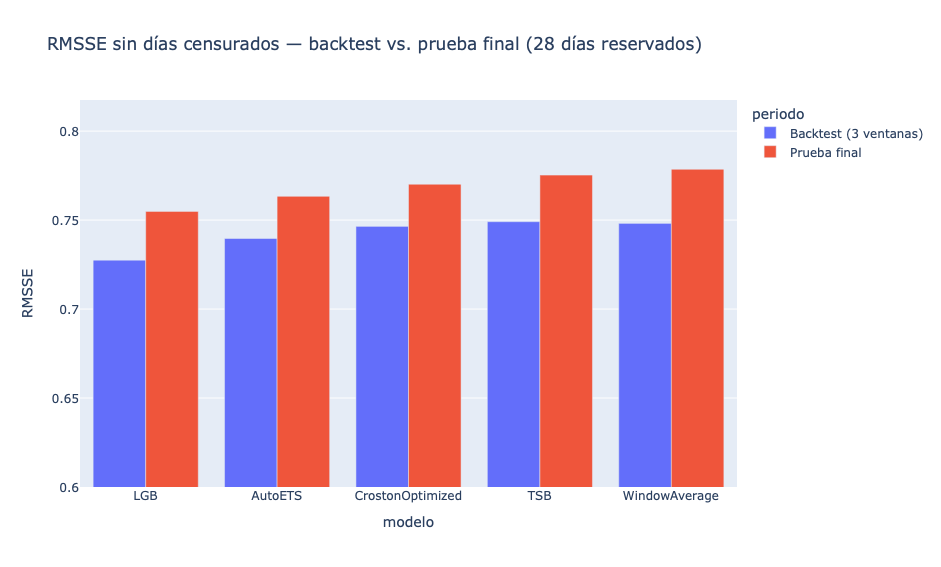

In [7]:
abc = seg.select(unique_id=pl.col("id").cast(pl.Utf8), abc="abc").to_pandas()
pl_ = prueba[~prueba["excluir"]].merge(abc, on="unique_id", how="left")
ver = ["AutoETS", "TSB", "CrostonOptimized", "WindowAverage", "LGB"]
por_abc = pd.concat({g: calcular_metricas(pl_[pl_["abc"] == g], ver).set_index("modelo")["RMSSE"]
                     for g in ["A", "B", "C"]}, axis=1).T
por_abc.to_csv(REP / "prueba_final_por_abc_CA_1.csv")
display(por_abc.round(3).style.highlight_min(axis=1, color="#c6efce"))

graf = (final[final["modelo"].isin(ver)]
        .melt(id_vars="modelo", value_vars=["RMSSE_backtest", "RMSSE_limpio"],
              var_name="periodo", value_name="RMSSE")
        .replace({"periodo": {"RMSSE_backtest": "Backtest (3 ventanas)", "RMSSE_limpio": "Prueba final"}}))
fig = px.bar(graf, x="modelo", y="RMSSE", color="periodo", barmode="group",
             title="RMSSE sin días censurados — backtest vs. prueba final (28 días reservados)")
fig.update_layout(width=950, height=550, yaxis_range=[0.6, graf["RMSSE"].max() * 1.05])
fig.write_html(FIG_DIR / "09_prueba_final.html", include_plotlyjs="cdn")
try:
    fig.write_image(FIG_DIR / "09_prueba_final.png", scale=2)
except Exception as e:
    print(f"PNG no generado ({e})")
fig.show()

In [8]:
## Resultados — Walmart CA_1 (3,041 productos)

#> **Nota:** la ablación de `06_ablacion_censura` muestra que el ahorro de inventario frente a TSB viene de corregir la demanda censurada, no del modelo: TSB y AutoETS entrenados con demanda corregida igualan a LightGBM.

#**Pronóstico** (RMSSE sin días censurados; backtest de 3 ventanas + prueba final reservada de 28 días)
#- LightGBM es el mejor modelo en el backtest (0.727 vs. 0.740 de AutoETS) y en la prueba final (0.755 vs. 0.763), con el mismo orden de modelos en ambos.
#- La mejora en precisión es modesta (1–3%); el aporte principal es eliminar el sesgo: −1.0% vs. entre −4% y −8% de los métodos clásicos, que subestiman la demanda real al entrenarse con ventas censuradas por agotados.

#**Inventario** (política (R,S), 2,467 productos, 26 revisiones semanales)
#- Con el mismo fill rate de 95%, LightGBM requiere 25% menos inventario que TSB (de 20% a ~45% según el nivel de servicio).
#- En su nivel de servicio óptimo, el costo total es 26% menor que con TSB y 36% menor que con SeasonalNaive.
#- La ventaja se mantiene en los 9 escenarios de costos evaluados (18–40% de ahorro vs. TSB).

#**Metodología**
#- Detección de demanda censurada sin datos de inventario: 9.9% de días-producto inactivos y 2.7% de agotados probables (rango de sensibilidad: 0.9–7.2%), excluidos del entrenamiento y de la evaluación.
#- Stock de seguridad calibrado con errores empíricos fuera de muestra, por clase de demanda × quintil de volumen (04_inventario, celda 10).
#- Prueba final evaluada una sola vez, sin ajustes posteriores.